# Previsão de Churn em Telecomunicações
**Trabalho de Machine Learning, Unidade 3**

Integrantes: Karoline Costa e Gabriel Sad

## 1. Definição do problema
*Churn* é o cancelamento do serviço por um cliente. Reter clientes costuma custar menos que conquistar novos, então identificar quem tem risco de sair permite agir antes (ofertas, contato do suporte, mudança de plano).

- **Tipo:** classificação binária supervisionada (`Churn` = Yes/No).
- **Métricas prioritárias:** *recall* (não deixar escapar quem vai cancelar) e *F1* (sem gerar alarmes falsos demais).

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

SEED = 42
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
RES = Path("resultados"); RES.mkdir(exist_ok=True)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIG / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Dados
Base pública **Telco Customer Churn** (Kaggle). Coloque o `.zip` ou o `.csv` na mesma pasta do notebook. No Colab, se não houver arquivo, abre-se uma janela de upload.

In [2]:
def localizar_csv():
    def procurar():
        return sorted(p for p in Path(".").rglob("*.csv")
                      if "churn" in p.name.lower() and "resultados" not in p.parts)
    def extrair():
        for z in Path(".").glob("*.zip"):
            if "churn" in z.name.lower():
                zipfile.ZipFile(z).extractall("dados")
    extrair()
    if not procurar():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError("Coloque o ZIP ou CSV do Telco Customer Churn nesta pasta.")
        files.upload()
        extrair()
    return procurar()[0]

caminho = localizar_csv()
df = pd.read_csv(caminho)

esperadas = {"customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"}
faltando = esperadas - set(df.columns)
assert not faltando, f"Colunas ausentes em {caminho}: {faltando}"

print(caminho, df.shape)
df.head()

WA_Fn-UseC_-Telco-Customer-Churn.csv (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print("\nDistribuição do alvo:")
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Limpeza
- `TotalCharges` pode vir como texto, com campos em branco: convertemos para número. Em clientes com `tenure = 0` (ainda sem fatura), o total é 0.
- Removemos duplicatas e o identificador `customerID`, que não tem valor preditivo.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges ausentes:", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0

antes = len(df)
df = df.drop_duplicates(subset="customerID").drop(columns="customerID")
print("Duplicatas removidas:", antes - len(df))

df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
y = df.pop("Churn").map({"No": 0, "Yes": 1})
assert y.notna().all(), "Há valores inesperados em Churn"
X = df

TotalCharges ausentes: 11
Duplicatas removidas: 0


## 4. Divisão em treino (60%), validação (20%) e teste (20%)
Divisão estratificada, feita **antes** de ajustar normalização e codificação, para evitar vazamento de dados.

- **Treino:** ajuste dos modelos e Grid Search com validação cruzada.
- **Validação:** escolha do limiar de decisão e do modelo final.
- **Teste:** avaliação final.

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
for nome, alvo in [("treino", y_train), ("validação", y_val), ("teste", y_test)]:
    print(f"{nome:10s} n={len(alvo):5d}  churn={alvo.mean():.1%}")

treino     n= 4225  churn=26.5%
validação  n= 1409  churn=26.5%
teste      n= 1409  churn=26.5%


## 5. Análise exploratória (somente no treino)

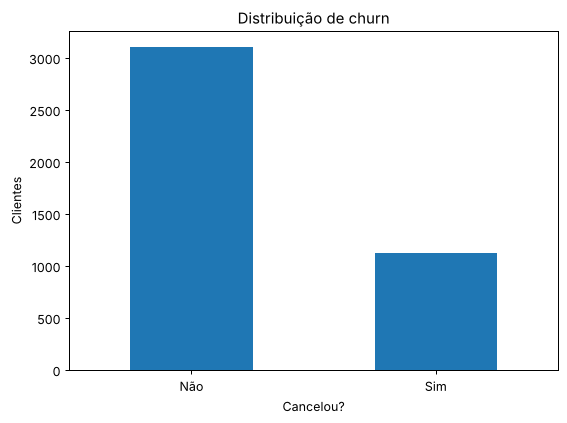

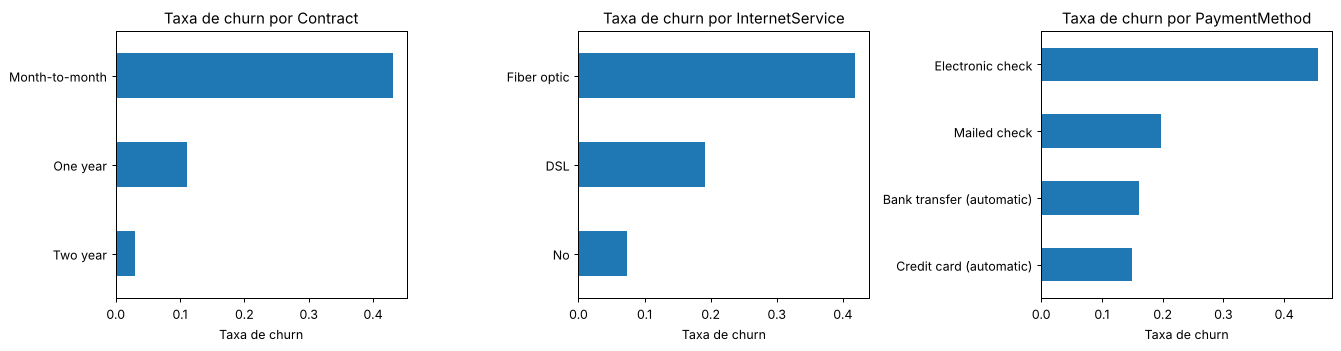

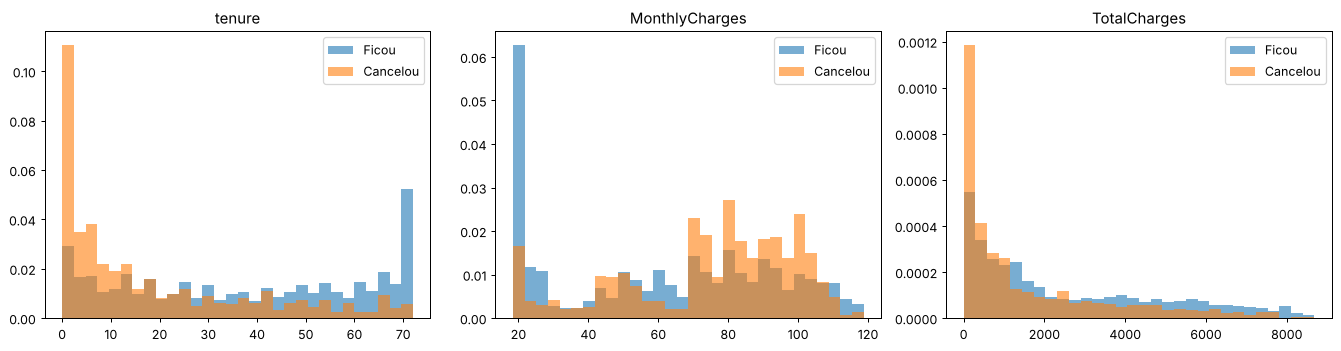

In [6]:
treino = X_train.assign(Churn=y_train)

ax = y_train.map({0: "Não", 1: "Sim"}).value_counts().plot.bar(rot=0)
ax.set(title="Distribuição de churn", xlabel="Cancelou?", ylabel="Clientes")
salvar("01_distribuicao_churn")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(eixos, ["Contract", "InternetService", "PaymentMethod"]):
    treino.groupby(col)["Churn"].mean().sort_values().plot.barh(ax=ax)
    ax.set(title=f"Taxa de churn por {col}", xlabel="Taxa de churn", ylabel="")
salvar("02_churn_por_categoria")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(eixos, ["tenure", "MonthlyCharges", "TotalCharges"]):
    bins = np.histogram_bin_edges(treino[col].dropna(), bins=30)
    for valor, rotulo in [(0, "Ficou"), (1, "Cancelou")]:
        ax.hist(treino.loc[treino["Churn"] == valor, col].dropna(), bins=bins, alpha=0.6, density=True, label=rotulo)
    ax.set(title=col); ax.legend()
salvar("03_variaveis_numericas")

## 6. Pré-processamento
- Numéricas: imputação pela mediana e padronização (`StandardScaler`).
- Categóricas: imputação pela moda e `OneHotEncoder`.

Tudo fica dentro de um `Pipeline`, ajustado apenas nos dados de treino de cada dobra.

In [7]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
categoricas = [c for c in X.columns if c not in numericas]

preprocessador = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("esc", StandardScaler())]), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), categoricas),
])

## 7. Modelagem e ajuste de hiperparâmetros
Comparamos **Regressão Logística**, **Random Forest** e **SVM**, além de um classificador trivial como referência. O Grid Search usa validação cruzada estratificada com 5 dobras, otimizando F1.

In [8]:
modelos = {
    "Regressão Logística": (LogisticRegression(max_iter=5000),
        {"modelo__C": [0.01, 0.1, 1, 10, 100], "modelo__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED),
        {"modelo__n_estimators": [200, 400], "modelo__max_depth": [5, 10, None],
         "modelo__min_samples_leaf": [1, 5, 10], "modelo__class_weight": [None, "balanced"]}),
    "SVM": (SVC(),
        {"modelo__C": [0.1, 1, 10], "modelo__kernel": ["linear", "rbf"],
         "modelo__class_weight": [None, "balanced"]}),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

buscas, linhas = {}, []
for nome, (modelo, grade) in modelos.items():
    pipe = Pipeline([("pre", preprocessador), ("modelo", modelo)])
    busca = GridSearchCV(pipe, grade, cv=cv, scoring="f1", n_jobs=-1)
    busca.fit(X_train, y_train)
    buscas[nome] = busca
    i = busca.best_index_
    linhas.append({"Modelo": nome, "F1 (CV)": busca.best_score_,
                   "Desvio": busca.cv_results_["std_test_score"][i],
                   "Melhores hiperparâmetros": {k.split("__")[1]: v for k, v in busca.best_params_.items()}})

tabela_cv = pd.DataFrame(linhas).set_index("Modelo")
tabela_cv.to_csv(RES / "validacao_cruzada.csv")
tabela_cv

,F1 (CV),Desvio,Melhores hiperparâmetros
Modelo,,,
Regressão Logística,0.621274,0.022551,"{'C': 0.01, 'class_weight': 'balanced'}"
Random Forest,0.631973,0.020584,"{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 400}"
SVM,0.620749,0.023058,"{'C': 0.1, 'class_weight': 'balanced', 'kernel': 'rbf'}"


## 8. Validação: limiar de decisão e escolha do modelo
Por padrão o corte é 0,5 de probabilidade (ou 0 na função de decisão do SVM). Para cada modelo, buscamos no conjunto de **validação** o corte de maior F1. O modelo final é o de melhor F1 de validação.

Como o corte é escolhido na própria validação, o F1 dela é um pouco otimista; a estimativa imparcial é a do teste.

In [9]:
def pontuacoes(modelo, dados):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(dados)[:, 1]
    return modelo.decision_function(dados)

def avaliar(real, previsto, score):
    return {"Acurácia": accuracy_score(real, previsto),
            "Precisão": precision_score(real, previsto, zero_division=0),
            "Recall": recall_score(real, previsto),
            "F1": f1_score(real, previsto),
            "ROC-AUC": roc_auc_score(real, score),
            "PR-AUC": average_precision_score(real, score)}

limiares, linhas = {}, {}
for nome, busca in buscas.items():
    s = pontuacoes(busca.best_estimator_, X_val)
    p, r, t = precision_recall_curve(y_val, s)
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    limiares[nome] = t[np.argmax(f1)]
    linhas[nome] = {**avaliar(y_val, (s >= limiares[nome]).astype(int), s), "Limiar": limiares[nome]}

tabela_val = pd.DataFrame(linhas).T
tabela_val.to_csv(RES / "validacao.csv")
melhor = tabela_val["F1"].idxmax()
print("Modelo final escolhido:", melhor)
tabela_val.round(3)

Modelo final escolhido: Random Forest


,Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC,Limiar
Regressão Logística,0.807,0.628,0.671,0.649,0.855,0.668,0.655
Random Forest,0.768,0.542,0.813,0.650,0.857,0.673,0.485
SVM,0.797,0.601,0.698,0.646,0.847,0.656,0.595


## 9. Avaliação no conjunto de teste

In [10]:
trivial = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
linhas = {"Referência (sempre 'Não')": avaliar(y_test, trivial.predict(X_test), pontuacoes(trivial, X_test))}
previsoes = {}
for nome, busca in buscas.items():
    est = busca.best_estimator_
    s = pontuacoes(est, X_test)
    linhas[f"{nome} (padrão)"] = avaliar(y_test, est.predict(X_test), s)
    previsoes[nome] = (s >= limiares[nome]).astype(int)
    linhas[f"{nome} (limiar ajustado)"] = avaliar(y_test, previsoes[nome], s)

tabela_teste = pd.DataFrame(linhas).T
tabela_teste.to_csv(RES / "teste.csv")
tabela_teste.round(3)

,Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC
Referência (sempre 'Não'),0.735,0.000,0.000,0.000,0.50,0.265
Regressão Logística (padrão),0.741,0.508,0.805,0.623,0.83,0.621
Regressão Logística (limiar ajustado),0.779,0.578,0.626,0.601,0.83,0.621
Random Forest (padrão),0.752,0.522,0.773,0.623,0.83,0.629
Random Forest (limiar ajustado),0.749,0.518,0.789,0.625,0.83,0.629
SVM (padrão),0.732,0.498,0.816,0.618,0.82,0.585
SVM (limiar ajustado),0.772,0.561,0.650,0.602,0.82,0.585


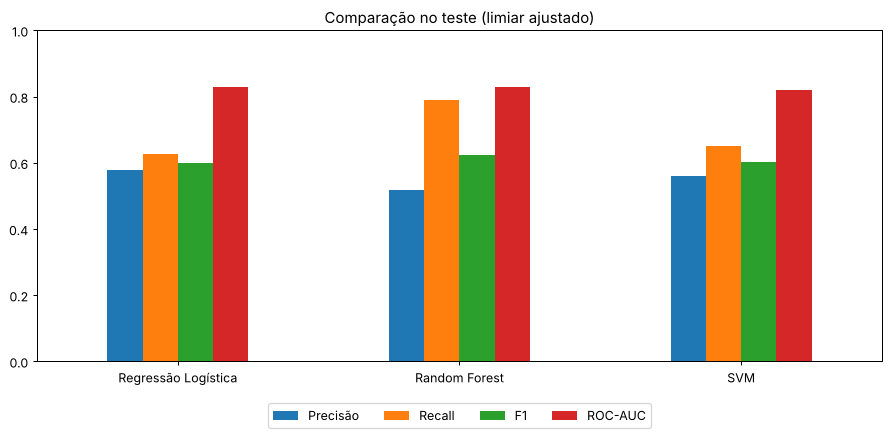

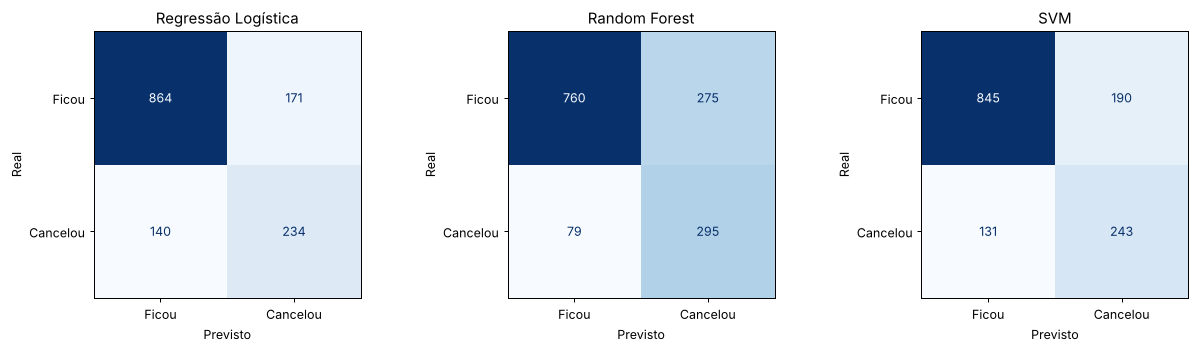

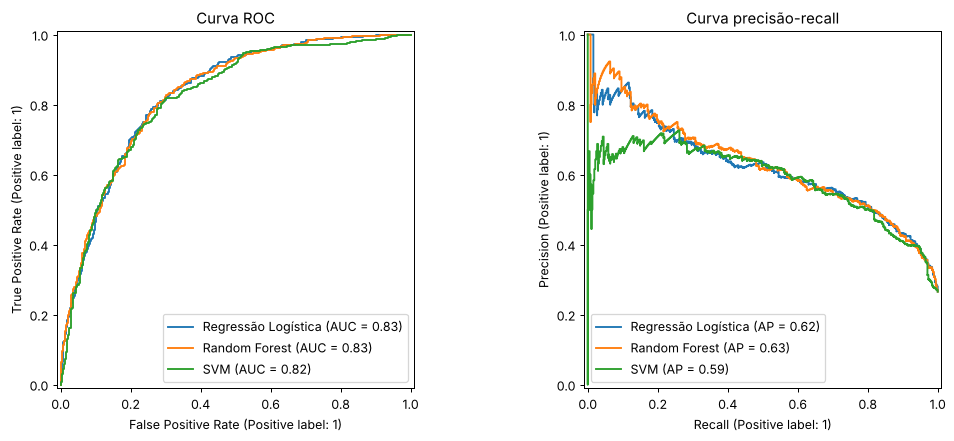

In [11]:
ajustados = tabela_teste[tabela_teste.index.str.contains("ajustado")]
ajustados.index = ajustados.index.str.replace(" (limiar ajustado)", "", regex=False)
ax = ajustados[["Precisão", "Recall", "F1", "ROC-AUC"]].plot.bar(rot=0, figsize=(10, 5))
ax.set(title="Comparação no teste (limiar ajustado)", ylim=(0, 1), xlabel="")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=4)
salvar("04_comparacao_metricas")

fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, pred) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Ficou", "Cancelou"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=nome, xlabel="Previsto", ylabel="Real")
salvar("05_matrizes_confusao")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
for nome, busca in buscas.items():
    s = pontuacoes(busca.best_estimator_, X_test)
    RocCurveDisplay.from_predictions(y_test, s, name=nome, ax=a1)
    PrecisionRecallDisplay.from_predictions(y_test, s, name=nome, ax=a2)
a1.set_title("Curva ROC"); a2.set_title("Curva precisão-recall")
salvar("06_curvas")

## 10. Importância das variáveis
Importância por permutação, calculada na validação: quanto o F1 (no corte padrão) cai ao embaralhar cada variável.

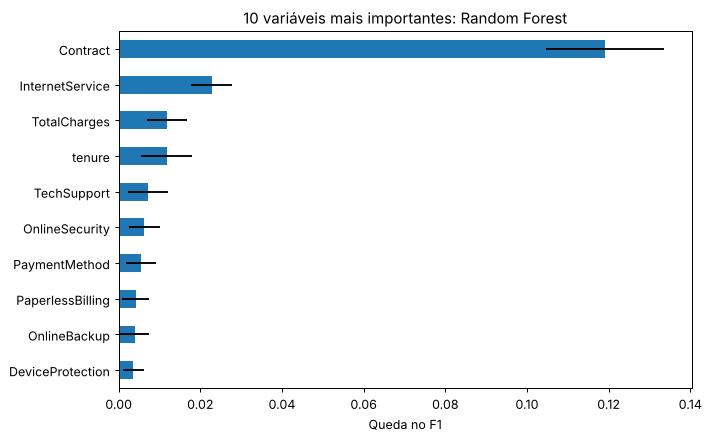

In [12]:
imp = permutation_importance(buscas[melhor].best_estimator_, X_val, y_val, scoring="f1",
                             n_repeats=20, random_state=SEED, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X.columns).sort_values()
importancia.sort_values(ascending=False).to_csv(RES / "importancia.csv", header=["queda_F1"])
ax = importancia.tail(10).plot.barh(figsize=(8, 5),
                                    xerr=pd.Series(imp.importances_std, index=X.columns)[importancia.tail(10).index])
ax.set(title=f"10 variáveis mais importantes: {melhor}", xlabel="Queda no F1")
salvar("07_importancia")

## 11. Resumo dos resultados

In [13]:
final = tabela_teste.loc[f"{melhor} (limiar ajustado)"]
tn_fp_fn_tp = pd.crosstab(y_test, previsoes[melhor])
print(f"Modelo final: {melhor}")
print(final.round(3).to_string())
print(f"\nDos {int(y_test.sum())} clientes que cancelaram no teste, o modelo identificou "
      f"{int(((previsoes[melhor] == 1) & (y_test == 1)).sum())}.")
print(f"Alarmes falsos: {int(((previsoes[melhor] == 1) & (y_test == 0)).sum())}.")
print("Variáveis mais importantes:", ", ".join(importancia.index[::-1][:5]))

Modelo final: Random Forest
Acurácia    0.749
Precisão    0.518
Recall      0.789
F1          0.625
ROC-AUC     0.830
PR-AUC      0.629

Dos 374 clientes que cancelaram no teste, o modelo identificou 295.
Alarmes falsos: 275.
Variáveis mais importantes: Contract, InternetService, TotalCharges, tenure, TechSupport


## 12. Conclusões e melhorias futuras
- O Random Forest foi escolhido pela validação e detectou 79% dos cancelamentos no teste, com precisão de 52%.
- A diferença para a Regressão Logística é pequena; por ser mais simples e interpretável, ela é uma alternativa razoável.
- O tipo de contrato é o fator mais associado ao churn: no treino, 43,1% no mensal, 11,0% no anual e 2,9% no bienal.

Possíveis melhorias:
- Testar Gradient Boosting (XGBoost, LightGBM) e redes neurais.
- Criar variáveis, como número de serviços contratados.
- Comparar técnicas de balanceamento, como SMOTE.
- Escolher o limiar por validação cruzada e pelo custo real de uma retenção e de um cliente perdido.
- Calibrar as probabilidades e validar com dados mais recentes.